In [104]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.integrate import cumulative_trapezoid

%matplotlib inline

In [105]:
DATA_FULL = r"./_processed_profiles/stitched_profiles.csv"
df = pd.read_csv(DATA_FULL)

# Static storage sizing
Requirements described by:
$$E_{req} = \int P(t) \mathrm{d}t$$
$$P_{req} = \max P(t)$$

Requirements met by following systems:
$$N_{b} E_{b} \geq E_{req},$$
$$N_{b} P_{b} \geq P_{req}$$

Thus, feasible bat-only designs described by:
$$N_{b} = \max (\frac{E_{req}}{E_b}, \frac{P_{req}}{P_b})

In [106]:
df["energy_kWh"] = (
    df.groupby("segment_id")["node_gpu_power_W"]
    .transform(
        lambda x: cumulative_trapezoid(
            x,
            df.loc[x.index, "time_s"],
            initial=0
        ) / 3_600_000
    )
)

bat_only = df.groupby("segment_id").agg(
    P_req=("node_gpu_power_W", "max"),
    E_req=("energy_kWh", "last")
)

# Convert kWh to Wh
bat_only["E_req"] *= 1000

bat_only.head()

,P_req,E_req
segment_id,,
1,4638.2142,123.309949
2,5297.7384,126.231137
3,5774.4390,124.146737
4,5754.6242,247.967713
5,4638.2142,123.309949


In [107]:
# bat only example with SonyLFP
nom_volt_bat=3.2 # V
nom_cap_bat=3.0 # Ah
max_discharge_rate_bat = 6.6 # 1/h

E_b = nom_volt_bat * nom_cap_bat # Wh
P_b = nom_volt_bat * nom_cap_bat * max_discharge_rate_bat # using discharge rate, as we're only discharging in these trials!

bat_only["N_b_energy"] = np.ceil(bat_only["E_req"] / E_b).astype(int)
bat_only["N_b_power"] = np.ceil(bat_only["P_req"] / P_b).astype(int)

bat_only["N_b"] = bat_only[["N_b_energy", "N_b_power"]].max(axis=1)

# amount of cells power limited!
print(bat_only["N_b"].median(), bat_only["N_b"].max(), bat_only["N_b"].quantile(0.95))
bat_only.head()

85.0 120 114.0


,P_req,E_req,N_b_energy,N_b_power,N_b
segment_id,,,,,
1,4638.2142,123.309949,13,74,74
2,5297.7384,126.231137,14,84,84
3,5774.4390,124.146737,13,92,92
4,5754.6242,247.967713,26,91,91
5,4638.2142,123.309949,13,74,74


## Introducing supercaps

We can reformulate
$$N_{b} E_{b} + N_{sc} E_{sc} \geq E_{req},$$
$$N_{b} P_{b} + N_{sc} P_{sc} \geq P_{req}$$
to
$$N_b \geq \frac{E_{req}-N_{sc}E_{sc}}{E_b}$$
$$N_b \geq \frac{P_{req}-N_{sc}P_{sc}}{P_b}$$
and finally:
$$N_{b}(N_{sc}) = \max(\left\lceil \frac{E_{req}-N_{sc}E_{sc}}{E_b} \right\rceil, \left\lceil \frac{P_{req}-N_{sc}P_{sc}}{P_b} \right\rceil)$$

In [108]:
# 1 sc example
N_sc = 1

peak = bat_only.copy().drop(columns=["N_b_energy", "N_b_power", "N_b"])

capacitance = 3200.0    # F
rated_voltage = 2.85    # V
min_voltage = 1.425     # V

E_sc = (
    (rated_voltage**2 - min_voltage**2)
    * capacitance / 2 / 3600
)

P_sc = 11.3e3 # peak power!


peak["N_b_energy"] = np.ceil((peak["E_req"] - N_sc * E_sc) / E_b).astype(int)
peak["N_b_power"] = np.ceil((peak["P_req"] - N_sc * P_sc) / P_b).astype(int)

peak["N_b"] = peak[["N_b_energy", "N_b_power"]].max(axis=1)

print(peak["N_b_energy"].median(), peak["N_b_energy"].max(), peak["N_b_energy"].quantile(0.95))
print(peak["N_b_power"].median(), peak["N_b_power"].max(), peak["N_b_power"].quantile(0.95))

peak.head()

20.0 31 30.0
-94.0 -58 -64.05000000000001


,P_req,E_req,N_b_energy,N_b_power,N_b
segment_id,,,,,
1,4638.2142,123.309949,13,-105,13
2,5297.7384,126.231137,13,-94,13
3,5774.4390,124.146737,13,-87,13
4,5754.6242,247.967713,26,-87,26
5,4638.2142,123.309949,13,-105,13


Theoretically, 1 sc cell covers more than enough of the power requirements -> using peak_power as P_sc unrealistic.
We can use several (more or less conservative) values for P_sc approximation using:
$$P = I(V - IR)$$

In [109]:
R_int = 0.18e-3

def calc_P_sc(
        I,
        V,
        R
):
    return I*(V-I*R)

def calc_N_b(
        N_sc,
        P_sc
):
    df = bat_only.copy().drop(columns=["N_b_energy", "N_b_power", "N_b"])
    df["N_b_energy"] = np.ceil((df["E_req"] - N_sc * E_sc) / E_b).astype(int)
    df["N_b_power"] = np.ceil((df["P_req"] - N_sc * P_sc) / P_b).astype(int)

    df["N_b"] = df[["N_b_energy", "N_b_power"]].max(axis=1)

    return df

In [110]:
N_sc = 1

# most conservative approximation with I ^= Max continuous current, ΔT = 15°C and V ^= V_min
P_sc1 = calc_P_sc(167, 1.425, R_int)
print(P_sc1)
c1 = calc_N_b(1, P_sc1)
print(c1["N_b"].median(), c1["N_b"].max(), c1["N_b"].quantile(0.95), '\n')


# I ^= Max continuous current, ΔT = 15°C, V ^= avg(rated voltage, min_voltage)
P_sc2 = calc_P_sc(167, np.mean([1.425, 2.85]), R_int)
print(P_sc2)
c2 = calc_N_b(1, P_sc2)
print(c2["N_b"].median(), c2["N_b"].max(), c2["N_b"].quantile(0.95), '\n')

# I ^= Max continuous current, ΔT = 15°C, V ^= rated voltage
P_sc3 = calc_P_sc(167, 2.85, R_int)
print(P_sc3)
c3 = calc_N_b(1, P_sc3)
print(c3["N_b"].median(), c3["N_b"].max(), c3["N_b"].quantile(0.95), '\n')


# I ^= Maximum peak current for 1 second, V ^= rated voltage
P_sc4 = calc_P_sc(2890, 2.85, R_int)
print(P_sc4)
c4 = calc_N_b(1, P_sc4)
print(c4["N_b"].median(), c4["N_b"].max(), c4["N_b"].quantile(0.95), '\n')



232.95498
81.0 116 110.0 

351.94248
79.0 115 108.0 

470.92998
77.0 113 106.94999999999999 

6733.122
20.0 31 30.0 



In [111]:
medians = pd.DataFrame({
    "n_sc" : np.arange(0, 21),
    "N_b" : np.arange(0, 21),
    "N_b_energy" : np.arange(0, 21),
    "N_b_power" : np.arange(0, 21),
})

maxs = pd.DataFrame({
    "n_sc" : [],
    "N_b" : [],
    "N_b_energy" : [],
    "N_b_power" : []
})

p095s = pd.DataFrame({
    "n_sc" : [],
    "N_b" : [],
    "N_b_energy" : [],
    "N_b_power" : []
})


sc_range = np.arange(0, 31)
cols = ["N_b", "N_b_energy", "N_b_power"]

def calc_stats(P_sc):
    stats = (
        pd.concat(
            [
                calc_N_b(n_sc, P_sc).assign(n_sc=n_sc)
                for n_sc in sc_range
            ],
            ignore_index=True
        )
        .groupby("n_sc")[cols]
        .agg(["median", "max", lambda x: x.quantile(0.95)])
    )

    return stats.rename(columns={"<lambda_0>": "p095"})


# Calculate statistics for all four P_sc values
stats1 = calc_stats(P_sc1)
stats2 = calc_stats(P_sc2)
stats3 = calc_stats(P_sc3)
stats4 = calc_stats(P_sc4)

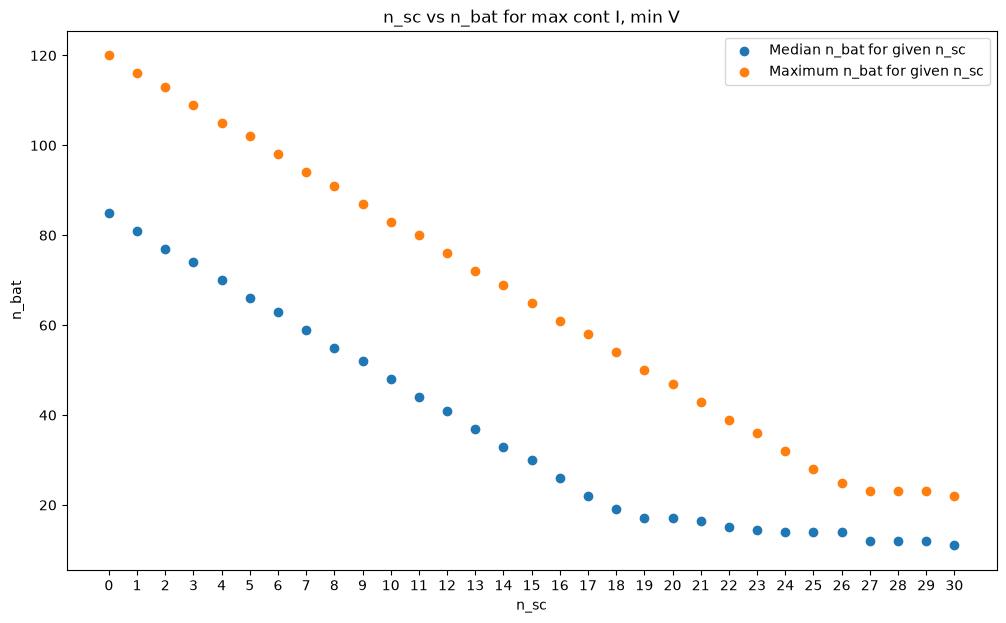

In [112]:
plt.figure(figsize=(12,7))

plt.scatter(
    stats1.index.to_list(),
    stats1["N_b"]["median"],
    label="Median n_bat for given n_sc",
)

plt.scatter(
    stats1.index.to_list(),
    stats1["N_b"]["max"],
    label="Maximum n_bat for given n_sc"
)

# plt.scatter(
#     stats.index.to_list(),
#     stats["N_b"]["p095"]
# )

plt.xticks(stats1.index.to_list())

plt.xlabel("n_sc")
plt.ylabel("n_bat")
plt.legend()

plt.title("n_sc vs n_bat for max cont I, min V")

plt.show()

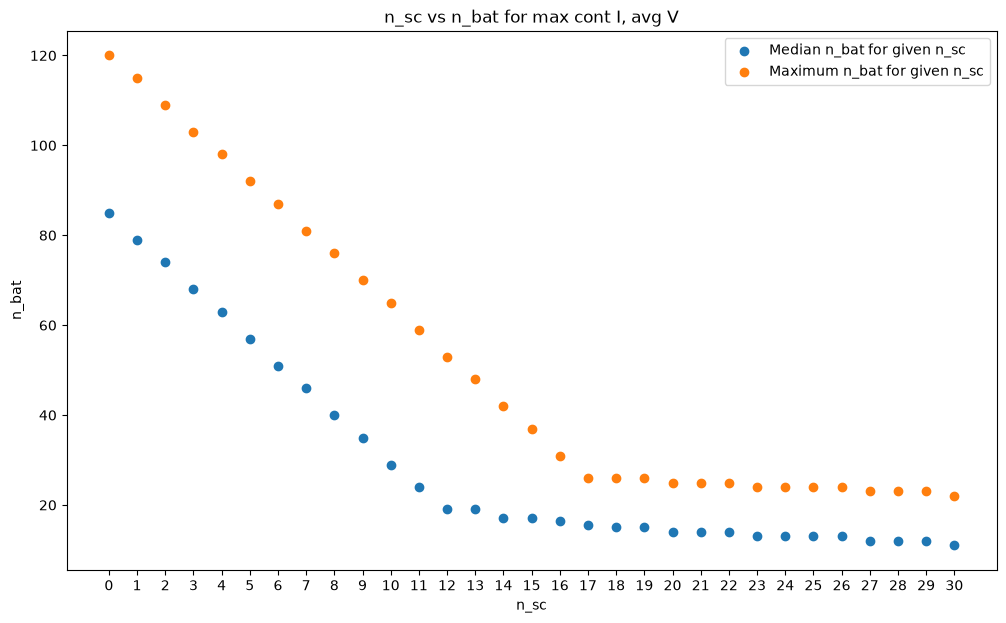

In [113]:
stats = stats2

plt.figure(figsize=(12,7))

plt.scatter(
    stats.index.to_list(),
    stats["N_b"]["median"],
    label="Median n_bat for given n_sc",
)

plt.scatter(
    stats.index.to_list(),
    stats["N_b"]["max"],
    label="Maximum n_bat for given n_sc"
)

# plt.scatter(
#     stats.index.to_list(),
#     stats["N_b"]["p095"]
# )

plt.xticks(stats.index.to_list())

plt.xlabel("n_sc")
plt.ylabel("n_bat")
plt.legend()

plt.title("n_sc vs n_bat for max cont I, avg V")

plt.show()

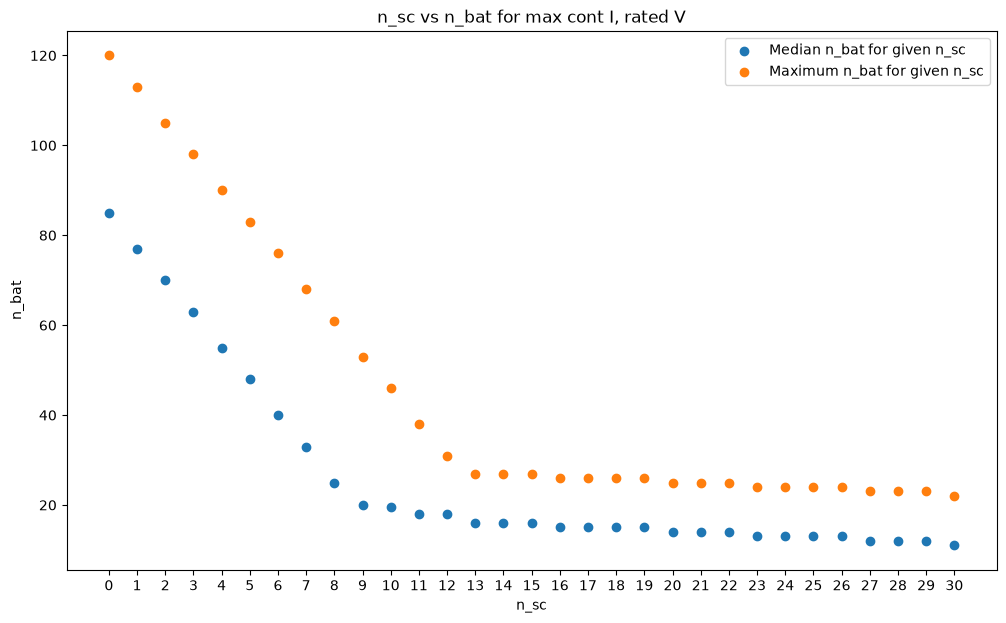

In [114]:
stats = stats3

plt.figure(figsize=(12,7))

plt.scatter(
    stats.index.to_list(),
    stats["N_b"]["median"],
    label="Median n_bat for given n_sc",
)

plt.scatter(
    stats.index.to_list(),
    stats["N_b"]["max"],
    label="Maximum n_bat for given n_sc"
)

# plt.scatter(
#     stats.index.to_list(),
#     stats["N_b"]["p095"]
# )

plt.xticks(stats.index.to_list())

plt.xlabel("n_sc")
plt.ylabel("n_bat")
plt.legend()

plt.title("n_sc vs n_bat for max cont I, rated V")

plt.show()

Optimal amount of supercaps ranges from 9 for the most optimal prediction to 26 for the most conservative (excluding p_sc = p_peak, where n_sc = 1) for around 20-30 bat cells

In [115]:
# "worst case" prediction, 26 sc, 25 bat
stats1["N_b"]["max"][26]

np.int64(25)

## Trying it out in sim

In [116]:
DATA_FULL = r"./_processed_profiles/stitched_profiles.csv"
df = pd.read_csv(DATA_FULL)

y = -df.loc[df["segment_id"] == 1]["node_gpu_power_W"]
p_bat_init = y[0]
y = y[1:]
x = np.diff(df.loc[df["segment_id"] == 1]["time_s"])

In [137]:
from itertools import product

from optimise import eval_configs, select_valid

ps_hybrid = {
    "tau": [0.001, 0.1, 1, 5, 10, 100, 250, 1000],
    "bat_series": range(20, 36, 5),
    "bat_parallel": [1],
    "sc_series": range(1, 36, 5),
    "sc_parallel": [1],
    "start_soc_bat" : [1],
    "start_soc_sc" : [1]

}

conf_hybrid = [
    dict(zip(ps_hybrid.keys(), combination))
    for combination in product(*ps_hybrid.values())
]

In [138]:
res_hybrid = eval_configs(conf_hybrid, x, y, p_bat_init, logging=False)

In [139]:
valid_hybrid = select_valid(res_hybrid, error_threshold=0.005)
valid_hybrid.head()

,tau,bat_series,bat_parallel,sc_series,sc_parallel,start_soc_bat,start_soc_sc,loss_fraction,error_fraction,e_total_loss,e_total_error,e_bat_thr,e_sc_thr
6,0.001,20,1,31,1,1,1,0.141956,1.639010e-18,17.504852,2.021099e-16,48.71628,74.595957
12,0.001,25,1,26,1,1,1,0.176957,1.741448e-18,21.820980,2.147418e-16,60.89535,62.416887
13,0.001,25,1,31,1,1,1,0.176507,1.741448e-18,21.765456,2.147418e-16,60.89535,62.416887
18,0.001,30,1,21,1,1,1,0.212025,7.170667e-19,26.145327,8.842310e-17,73.07442,50.237817
19,0.001,30,1,26,1,1,1,0.211493,7.170667e-19,26.079655,8.842310e-17,73.07442,50.237817


In [140]:
conf_opt_hybrid = [conf_hybrid[i] for i in valid_hybrid.index]
res_opt_hybrid = eval_configs(
    conf_opt_hybrid,
    x,
    y,
    p_bat_init,
    logging=True
)

tau = 0.001
n_bat = 25
n_sc = 26
 Battery SOC 0.6701833333333581
 Supercap SOC 0.15392686636329794
 Loss fraction 0.17695713163504365
 Error fraction 1.7414476502111493e-18


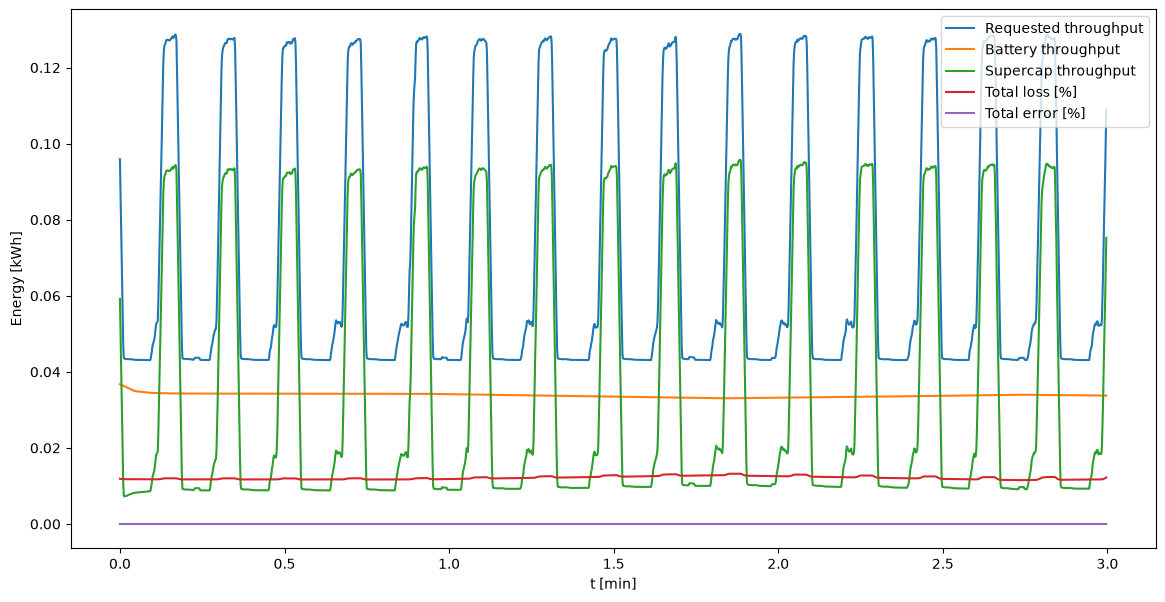

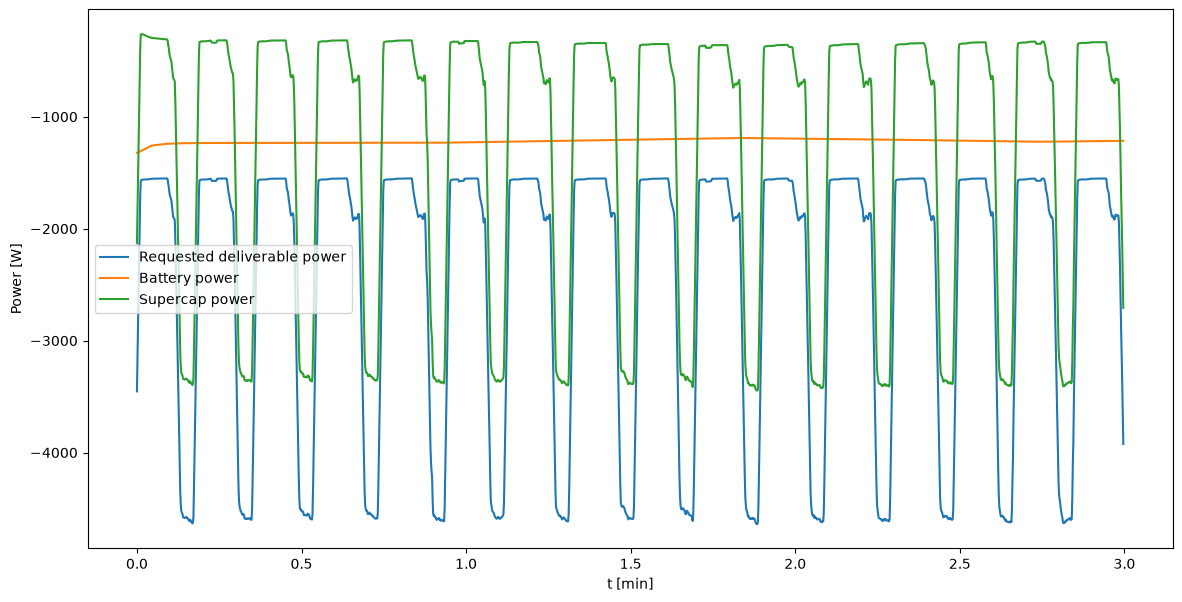

In [143]:
from plot import plot_simulation

i = 1
x_axis = res_opt_hybrid[i]["log"].index / 600

print( "tau =", res_opt_hybrid[i]["tau"])
print( "n_bat =", res_opt_hybrid[i]["bat_series"])
print( "n_sc =", res_opt_hybrid[i]["sc_series"])

plot_simulation(res_opt_hybrid, x_axis, i)

Best faith conditions (i.e. assuming the lowest P_sc) we satisfy a trial, with charge left over; Additionally scaling up the system does result in lower though.

How about "battery only" system (from above)?

In [144]:
from itertools import product

from optimise import eval_configs, select_valid

ps_bat = {
    "tau": [0.000001],
    "bat_series": range(65, 125, 5),
    "bat_parallel": [1],
    "sc_series": [1],
    "sc_parallel": [1]
}

conf_bat = [
    dict(zip(ps_bat.keys(), combination))
    for combination in product(*ps_bat.values())
]

In [145]:
res_bat = eval_configs(conf_bat, x, y, p_bat_init, logging=False)

In [146]:
valid_bat = select_valid(res_bat, error_threshold=0.005)
valid_bat

,tau,bat_series,bat_parallel,sc_series,sc_parallel,loss_fraction,error_fraction,e_total_loss,e_total_error,e_bat_thr,e_sc_thr
6,0.000001,95,1,1,1,0.235108,0.0,28.991633,0.0,121.962879,1.349358
7,0.000001,100,1,1,1,0.224548,0.0,27.689568,0.0,123.280061,0.032176
8,0.000001,105,1,1,1,0.204066,0.0,25.163854,0.0,123.312237,0.000000
9,0.000001,110,1,1,1,0.187308,0.0,23.097385,0.0,123.312237,0.000000
10,0.000001,115,1,1,1,0.173435,0.0,21.386672,0.0,123.312237,0.000000
11,0.000001,120,1,1,1,0.161693,0.0,19.938722,0.0,123.312237,0.000000


In [147]:
# regenerate x best performing configs with full logging
conf_opt_bat = [conf_bat[i] for i in valid_bat.index]
res_opt_bat = eval_configs(
    conf_opt_bat,
    x,
    y,
    p_bat_init,
    logging=True
)

bat_series = 105
 Battery SOC 0.4571902719498444
 Supercap SOC 0.6
 Loss fraction 0.20406615116641882
 Error fraction 0.0


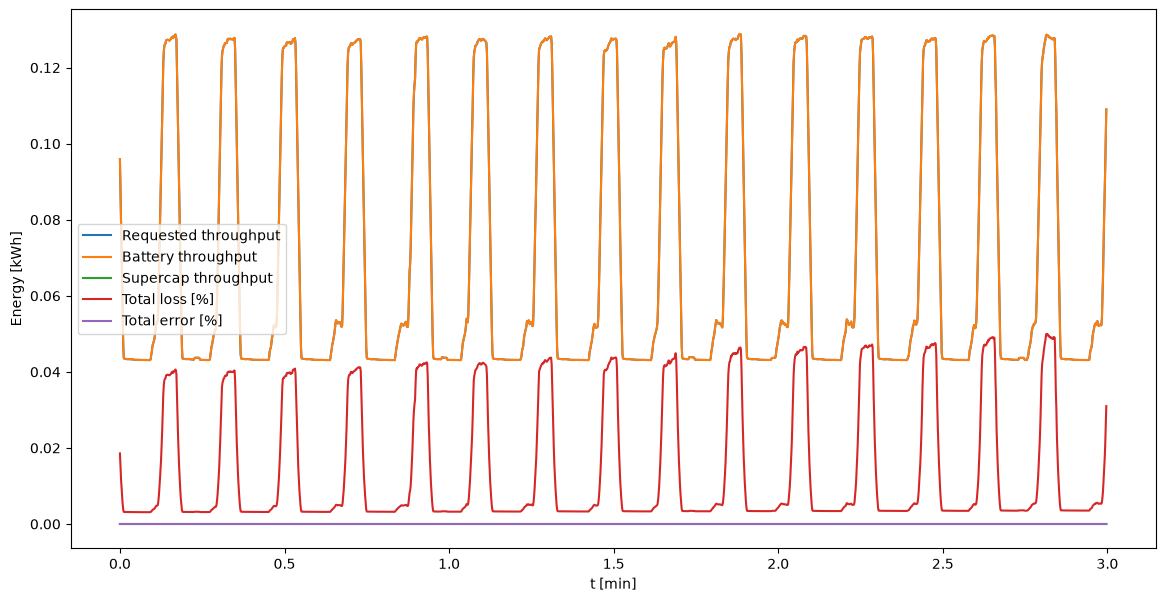

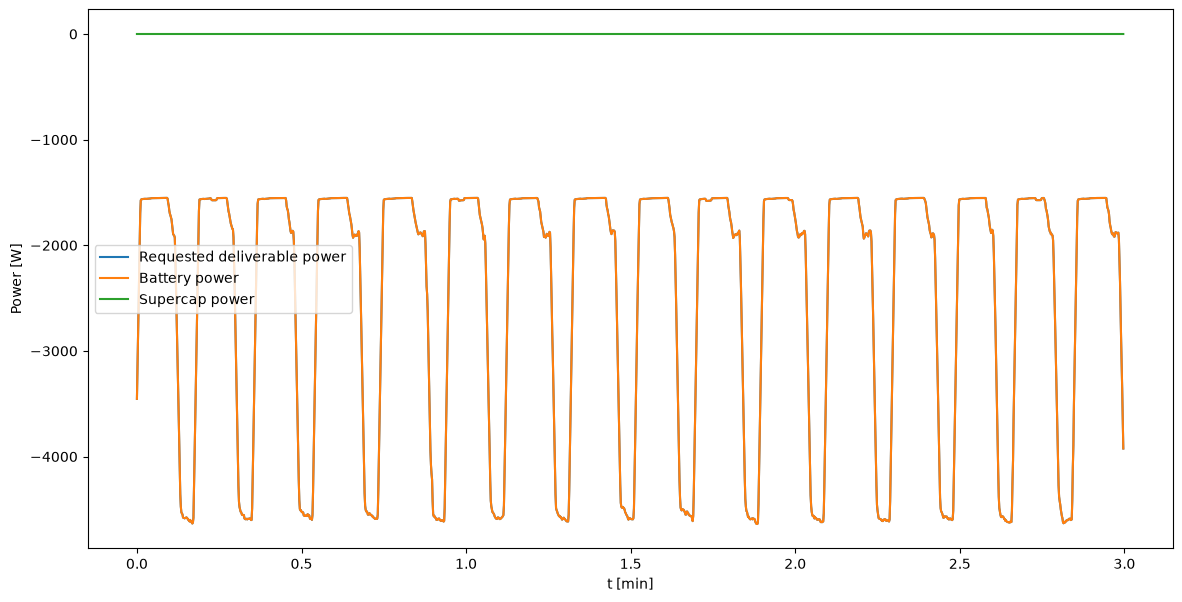

In [148]:
from plot import plot_simulation

i = 2
x_axis = res_opt_bat[i]["log"].index / 600

print( "bat_series =", res_opt_bat[i]["bat_series"])

plot_simulation(res_opt_bat, x_axis, i)

n_bat falls within the predicted range of (mean 85, max 120) (HybridController class needs SC by definition - didn't want to rewrite it just for this, with n_bat = 95, there is still some sc participation (although possibly not necessary), with 105 there is none.)